### Step 1: Generate Correlated 2D Data
We will start by creating a synthetic 2D dataset. Imagine we measure two features, $X$ and $Y$, that are highly correlated (for example, height and weight). We want to see how PCA can help us simplify this data.

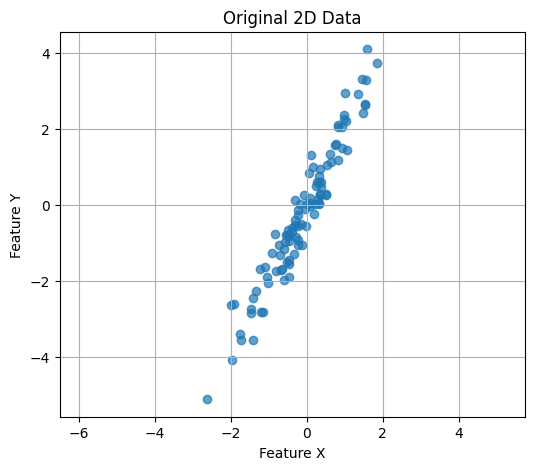

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)

# Generate 100 random points
x = np.random.normal(0, 1, 100)
y = 2 * x + np.random.normal(0, 0.5, 100)  # y is strongly related to x

# Combine them into a 2D dataset (matrix)
X = np.column_stack((x, y))

# Plot the raw dataset
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], alpha=0.7, color='C0')
plt.title("Original 2D Data")
plt.xlabel("Feature X")
plt.ylabel("Feature Y")
plt.grid(True)
plt.axis('equal')
plt.show()

### Step 2: Fit PCA using Scikit-Learn
Now we initialize and fit the PCA model. PCA finds the "directions" (Principal Components) along which our data varies the most.

In [ ]:
from sklearn.decomposition import PCA

# We fit PCA on our 2D data
pca = PCA(n_components=2)
pca.fit(X)

# Let's inspect the directions PCA found
for i, (variance, vector) in enumerate(zip(pca.explained_variance_, pca.components_)):
    print(f"Principal Component {i+1}: Direction {vector}, Variance explained: {variance:.3f}")

Principal Component 1: Direction [0.44011603 0.89794091], Variance explained: 4.070
Principal Component 2: Direction [ 0.89794091 -0.44011603], Variance explained: 0.045


### Step 3: Dimensionality Reduction (2D to 1D)
Now we project our data onto the first principal component (the direction with the most variance), effectively reducing its dimensionality from 2D to 1D.

In [ ]:
# Transform our 2D data into its PCA coordinate space
X_pca = pca.transform(X)

# Project the data back to the original space, keeping ONLY the first component
X_reconstructed = pca.inverse_transform(X_pca * [1, 0])

### Step 4: Visualizing the Results
Let's plot the original data alongside the 1D projection. You can see how the 2D cloud of points has been squashed onto a single line (the green dots).

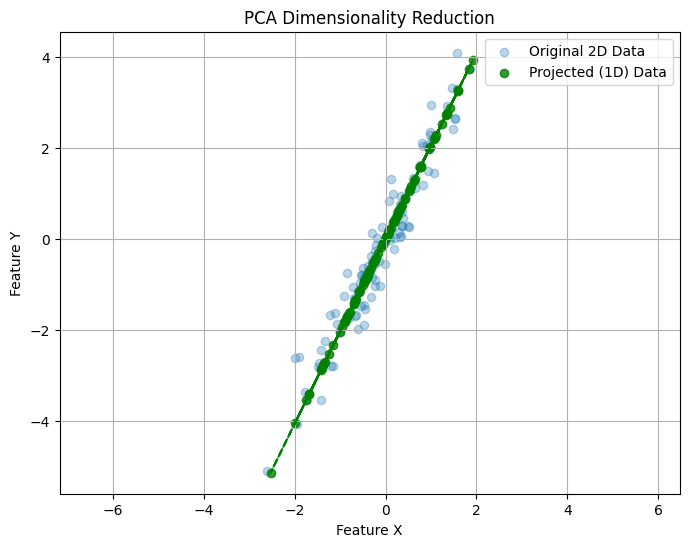

Percentage of information (variance) preserved in 1D: 98.90%


In [ ]:
plt.figure(figsize=(8, 6))

# Plot original 2D data cloud
plt.scatter(X[:, 0], X[:, 1], alpha=0.3, label="Original 2D Data", color='C0')

# Plot 1D projected representation onto the main direction line
plt.scatter(X_reconstructed[:, 0], X_reconstructed[:, 1], color='green', alpha=0.8, label="Projected (1D) Data")
plt.plot(X_reconstructed[:, 0], X_reconstructed[:, 1], color='green', linestyle='--')

plt.title("PCA Dimensionality Reduction")
plt.xlabel("Feature X")
plt.ylabel("Feature Y")
plt.axis('equal')
plt.legend()
plt.grid(True)
plt.show()

print(f"Percentage of information (variance) preserved in 1D: {pca.explained_variance_ratio_[0]*100:.2f}%")